1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 546ms/step


I0000 00:00:1793648202.548226   49816 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1793648203.102458   49816 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 12 bytes spill stores, 12 bytes spill loads



1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


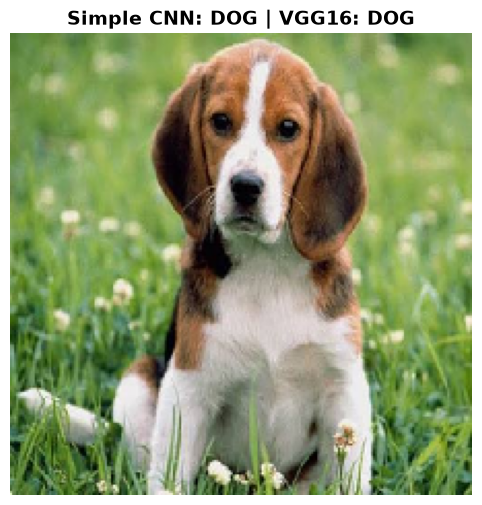

       MODEL COMPARISON RESULTS
1. Simple CNN Model:
   - Result: DOG
   - Cat: 48.55% | Dog: 51.45%

2. Fine-Tuned VGG16 Model:
   - Result: DOG
   - Cat: 35.52% | Dog: 64.48%


In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

model_simple = tf.keras.models.load_model('models/cats_vs_dogs_model.h5')
model_vgg = tf.keras.models.load_model('models/vgg16_cats_vs_dogs.h5')

img_path = 'images.jpg'
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)

img_simple_processed = img_batch / 255.0
pred_simple = model_simple.predict(img_simple_processed)
cat_prob_simple = pred_simple[0][0] * 100
dog_prob_simple = pred_simple[0][1] * 100
res_simple = "DOG" if dog_prob_simple > cat_prob_simple else "CAT"

img_vgg_processed = tf.keras.applications.vgg16.preprocess_input(img_batch.copy())
pred_vgg = model_vgg.predict(img_vgg_processed)
cat_prob_vgg = pred_vgg[0][0] * 100
dog_prob_vgg = pred_vgg[0][1] * 100
res_vgg = "DOG" if dog_prob_vgg > cat_prob_vgg else "CAT"

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title(f"Simple CNN: {res_simple} | VGG16: {res_vgg}", fontsize=14, fontweight='bold')
plt.show()

print("=" * 45)
print("       MODEL COMPARISON RESULTS")
print("=" * 45)
print(f"1. Simple CNN Model:")
print(f"   - Result: {res_simple}")
print(f"   - Cat: {cat_prob_simple:.2f}% | Dog: {dog_prob_simple:.2f}%\n")
print(f"2. Fine-Tuned VGG16 Model:")
print(f"   - Result: {res_vgg}")
print(f"   - Cat: {cat_prob_vgg:.2f}% | Dog: {dog_prob_vgg:.2f}%")
print("=" * 45)